In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost as xgb

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('DT-BrainCancer.csv')

df.head()

Saving DT-BrainCancer.csv to DT-BrainCancer (2).csv


,Unnamed: 0,sex,diagnosis,loc,ki,gtv,status
0,1,Female,Meningioma,Infratentorial,90,6.11,0
1,2,Male,HG glioma,Supratentorial,90,19.35,1
2,3,Female,Meningioma,Infratentorial,70,7.95,0
3,4,Female,LG glioma,Supratentorial,80,7.61,1
4,5,Male,HG glioma,Supratentorial,90,5.06,1


# 0. Introduction

# 1. Import Libraries

# 2. Load Dataset

# 3. Exploratory Data Analysis

# 4. Data Preprocessing

# 5. Feature Selection

# 6. Train-Test Split

# 7. Decision Tree Classifier

# 8. XGBoost Classifier

# 9. Model Evaluation and Comparison

# 10. Conclusion

In [3]:
import pandas as pd

df = pd.read_csv('/content/DT-BrainCancer.csv')

df.head()

,Unnamed: 0,sex,diagnosis,loc,ki,gtv,status
0,1,Female,Meningioma,Infratentorial,90,6.11,0
1,2,Male,HG glioma,Supratentorial,90,19.35,1
2,3,Female,Meningioma,Infratentorial,70,7.95,0
3,4,Female,LG glioma,Supratentorial,80,7.61,1
4,5,Male,HG glioma,Supratentorial,90,5.06,1


In [4]:
!pip install numpy pandas matplotlib scikit-learn xgboost

In [5]:
# ===== COMMON CELL v1 | identical in every notebook | DO NOT EDIT (report bugs to the group) =====
import os, json, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from xgboost import XGBClassifier, XGBRegressor

SEED = 42
os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)
print("sklearn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__)

# ---------------- split: top 70% train / next 15% validation / last 15% test ----------------
def split_70_15_15(df):
    n = len(df)
    i1 = int(round(0.70 * n))
    i2 = int(round(0.85 * n))
    return df.iloc[:i1].copy(), df.iloc[i1:i2].copy(), df.iloc[i2:].copy()

# ---------------- evaluation metrics, written from scratch (NO sklearn.metrics) ----------------
def confusion_matrix_np(y_true, y_pred, n_classes):
    """rows = true class, columns = predicted class (classes must be 0,1,2,...)"""
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[int(t), int(p)] += 1
    return cm

def accuracy_np(y_true, y_pred):
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))

def per_class_prf(cm):
    """precision, recall, f1 for every class (a 0/0 case is reported as 0)"""
    tp = np.diag(cm).astype(float)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    prec = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) > 0)
    rec = np.divide(tp, tp + fn, out=np.zeros_like(tp), where=(tp + fn) > 0)
    s = prec + rec
    f1 = np.divide(2 * prec * rec, s, out=np.zeros_like(tp), where=s > 0)
    return prec, rec, f1

def macro_prf(cm):
    """average (macro) precision, recall, f1 over all classes"""
    p, r, f = per_class_prf(cm)
    return float(p.mean()), float(r.mean()), float(f.mean())

def binary_metrics(y_true, y_pred):
    """positive class = 1"""
    cm = confusion_matrix_np(y_true, y_pred, 2)
    p, r, f = per_class_prf(cm)
    return {"accuracy": accuracy_np(y_true, y_pred), "precision": float(p[1]),
            "recall": float(r[1]), "f1": float(f[1]), "confusion_matrix": cm.tolist()}

def pr_curve_np(y_true, scores):
    """Precision-Recall curve. scores = predicted probability of class 1.
    returns precision[], recall[], thresholds[] (the curve starts at recall=0, precision=1)"""
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)
    order = np.argsort(-scores, kind="mergesort")          # highest score first
    ys, ss = y_true[order], scores[order]
    tps, fps = np.cumsum(ys), np.cumsum(1 - ys)
    idx = np.r_[np.where(np.diff(ss))[0], len(ss) - 1]     # last index of each distinct score
    precision = tps[idx] / (tps[idx] + fps[idx])
    recall = tps[idx] / ys.sum()
    return np.r_[1.0, precision], np.r_[0.0, recall], ss[idx]

def average_precision_np(precision, recall):
    """area under the PR curve (step-wise sum)"""
    return float(np.sum(np.diff(recall) * precision[1:]))

def mse_np(y_true, y_pred):
    d = np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float)
    return float(np.mean(d ** 2))

# ---------------- hyper-parameter search on the validation set ----------------
def run_grid(make_model, grid, X_tr, y_tr, X_va, y_va, score_fn, higher_is_better=True):
    """Train one model for every combination in `grid`, score on train and validation.
    Returns a table sorted best-first (ties keep the original order). Row 0 = the winner."""
    names = list(grid.keys())
    rows = []
    for combo in itertools.product(*[grid[k] for k in names]):
        params = dict(zip(names, combo))
        model = make_model(**params)
        model.fit(X_tr, y_tr)
        rows.append({**params,
                     "train_score": score_fn(y_tr, model.predict(X_tr)),
                     "val_score": score_fn(y_va, model.predict(X_va))})
    table = pd.DataFrame(rows)
    table = table.sort_values("val_score", ascending=not higher_is_better, kind="mergesort")
    return table.reset_index(drop=True)

def best_params(table, param_names):
    """read the winning row (row 0) as a plain python dict, ready for Model(**dict)"""
    out = {}
    for k in param_names:
        v = table.loc[0, k]
        out[k] = v.item() if hasattr(v, "item") else v
    return out

# ---------------- plotting helpers (they also save a 300-dpi PNG) ----------------
def plot_confusion(cm, labels, title, fname):
    cm = np.asarray(cm)
    fig, ax = plt.subplots(figsize=(5, 4.5))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(title)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    fig.tight_layout(); fig.savefig(fname, dpi=300); plt.show()

def plot_pr_curves(curves, baseline, title, fname):
    """curves = {"Decision Tree": (precision, recall, ap), "XGBoost": (...)}; baseline = share of positives"""
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    for name, (p, r, ap) in curves.items():
        ax.step(r, p, where="post", label=f"{name} (AP = {ap:.3f})")
    ax.axhline(baseline, ls="--", color="gray", label=f"No-skill ({baseline:.2f})")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.05); ax.set_title(title); ax.legend(loc="lower left")
    fig.tight_layout(); fig.savefig(fname, dpi=300); plt.show()

def plot_param_effect(table, param, ylabel, fname, title):
    """train vs validation score for each value of one hyper-parameter (best row for each value)"""
    best = table.drop_duplicates(subset=param).sort_values(param)
    x = best[param].astype(float)
    fig, ax = plt.subplots(figsize=(5.5, 4))
    ax.plot(x, best["train_score"], "o-", label="train")
    ax.plot(x, best["val_score"], "s-", label="validation")
    ax.set_xlabel(param); ax.set_ylabel(ylabel); ax.set_title(title); ax.legend()
    fig.tight_layout(); fig.savefig(fname, dpi=300); plt.show()

def plot_importances(feature_names, imp_dict, fname):
    """imp_dict = {"Decision Tree": array, "XGBoost": array}"""
    fig, axes = plt.subplots(1, len(imp_dict), figsize=(5.5 * len(imp_dict), 4), squeeze=False)
    for ax, (name, imp) in zip(axes[0], imp_dict.items()):
        order = np.argsort(imp)
        ax.barh(np.array(feature_names)[order], np.asarray(imp)[order])
        ax.set_title(f"{name}: feature importance")
    fig.tight_layout(); fig.savefig(fname, dpi=300); plt.show()

def plot_pred_vs_actual(y_true, preds, fname):
    """regression: scatter of predicted vs true values; the dashed line = perfect prediction"""
    fig, axes = plt.subplots(1, len(preds), figsize=(5 * len(preds), 4.5), squeeze=False)
    lo, hi = float(np.min(y_true)), float(np.max(y_true))
    for ax, (name, p) in zip(axes[0], preds.items()):
        ax.scatter(y_true, p, s=12, alpha=0.6)
        ax.plot([lo, hi], [lo, hi], "k--", lw=1)
        ax.set_xlabel("True value"); ax.set_ylabel("Predicted value"); ax.set_title(name)
    fig.tight_layout(); fig.savefig(fname, dpi=300); plt.show()

def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)
# ===== END OF COMMON CELL =====

sklearn 1.6.1 | xgboost 3.4.1 | pandas 2.2.3 | numpy 2.4.6


In [6]:
# [BC 1] Load and inspect
bc_raw = pd.read_csv("DT-BrainCancer.csv")
print("shape:", bc_raw.shape)
display(bc_raw.head())
print(bc_raw.dtypes)
print("missing values per column:"); print(bc_raw.isna().sum())
for c in ["sex", "diagnosis", "loc", "status"]:
    print(bc_raw[c].value_counts(dropna=False).to_dict())
display(bc_raw.describe())

shape: (88, 7)


,Unnamed: 0,sex,diagnosis,loc,ki,gtv,status
0,1,Female,Meningioma,Infratentorial,90,6.11,0
1,2,Male,HG glioma,Supratentorial,90,19.35,1
2,3,Female,Meningioma,Infratentorial,70,7.95,0
3,4,Female,LG glioma,Supratentorial,80,7.61,1
4,5,Male,HG glioma,Supratentorial,90,5.06,1


Unnamed: 0      int64
sex            object
diagnosis      object
loc            object
ki              int64
gtv           float64
status          int64
dtype: object
missing values per column:
Unnamed: 0    0
sex           0
diagnosis     1
loc           0
ki            0
gtv           0
status        0
dtype: int64
{'Female': 45, 'Male': 43}
{'Meningioma': 42, 'HG glioma': 22, 'Other': 14, 'LG glioma': 9, nan: 1}
{'Supratentorial': 69, 'Infratentorial': 19}
{0: 53, 1: 35}


,Unnamed: 0,ki,gtv,status
count,88.000000,88.000000,88.000000,88.000000
mean,44.500000,81.022727,8.660795,0.397727
std,25.547342,10.508866,8.657576,0.492233
min,1.000000,40.000000,0.010000,0.000000
25%,22.750000,80.000000,2.500000,0.000000
50%,44.500000,80.000000,6.510000,0.000000
75%,66.250000,90.000000,12.100000,1.000000
max,88.000000,100.000000,34.640000,1.000000


In [7]:
# [BC 2] Clean and encode
bc_df = bc_raw.drop(columns=["Unnamed: 0"]).copy()          # row-number column: not a real feature
bc_n_missing = int(bc_df["diagnosis"].isna().sum())
bc_df["diagnosis"] = bc_df["diagnosis"].fillna("Unknown")   # 1 missing value -> its own label
bc_df = pd.get_dummies(bc_df, columns=["sex", "diagnosis", "loc"], dtype=int)   # text -> 0/1 columns
bc_features = [c for c in bc_df.columns if c != "status"]
print("features:", bc_features)
display(bc_df.head())

features: ['ki', 'gtv', 'sex_Female', 'sex_Male', 'diagnosis_HG glioma', 'diagnosis_LG glioma', 'diagnosis_Meningioma', 'diagnosis_Other', 'diagnosis_Unknown', 'loc_Infratentorial', 'loc_Supratentorial']


,ki,gtv,status,sex_Female,sex_Male,diagnosis_HG glioma,diagnosis_LG glioma,diagnosis_Meningioma,diagnosis_Other,diagnosis_Unknown,loc_Infratentorial,loc_Supratentorial
0,90,6.11,0,1,0,0,0,1,0,0,1,0
1,90,19.35,1,0,1,1,0,0,0,0,0,1
2,70,7.95,0,1,0,0,0,1,0,0,1,0
3,80,7.61,1,1,0,0,1,0,0,0,0,1
4,90,5.06,1,0,1,1,0,0,0,0,0,1


In [8]:
# [BC 3] Split 70/15/15 (file order, as the assignment says) and baseline
bc_train, bc_val, bc_test = split_70_15_15(bc_df)
bc_X_train, bc_y_train = bc_train[bc_features].values, bc_train["status"].values
bc_X_val,   bc_y_val   = bc_val[bc_features].values,   bc_val["status"].values
bc_X_test,  bc_y_test  = bc_test[bc_features].values,  bc_test["status"].values

bc_split_counts = {}
for name, y in [("train", bc_y_train), ("val", bc_y_val), ("test", bc_y_test)]:
    bc_split_counts[name] = {"n": int(len(y)), "class0": int((y == 0).sum()), "class1": int((y == 1).sum())}
    print(name, bc_split_counts[name])

bc_baseline = binary_metrics(bc_y_test, np.zeros(len(bc_y_test), dtype=int))   # "always predict 0"
print("baseline (always predict 0) on test:", {k: round(v, 3) for k, v in bc_baseline.items() if k != "confusion_matrix"})

train {'n': 62, 'class0': 34, 'class1': 28}
val {'n': 13, 'class0': 9, 'class1': 4}
test {'n': 13, 'class0': 10, 'class1': 3}
baseline (always predict 0) on test: {'accuracy': 0.769, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}


,criterion,max_depth,min_samples_leaf,train_score,val_score
0,gini,3,10,0.701754,0.888889
1,gini,4,10,0.701754,0.888889
2,gini,5,10,0.701754,0.888889
3,entropy,3,10,0.701754,0.888889
4,entropy,4,10,0.701754,0.888889
5,entropy,5,10,0.701754,0.888889
6,gini,3,5,0.774194,0.727273
7,gini,3,3,0.779661,0.727273
8,gini,3,2,0.793103,0.727273
9,gini,3,1,0.779661,0.727273


how many settings tie with the best validation F1: 6
best Decision Tree settings: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 10} | validation F1: 0.8889


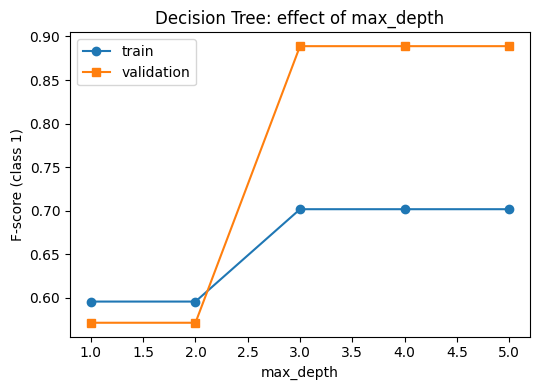

In [9]:
# [BC 4] Decision Tree tuning on VALIDATION (score = F-score of class 1)
def bc_score(y_true, y_pred):
    return binary_metrics(y_true, y_pred)["f1"]

bc_dt_grid = {"criterion": ["gini", "entropy"],
              "max_depth": [1, 2, 3, 4, 5],
              "min_samples_leaf": [10, 5, 3, 2, 1]}      # simplest first
bc_dt_table = run_grid(lambda **p: DecisionTreeClassifier(random_state=SEED, **p), bc_dt_grid,
                       bc_X_train, bc_y_train, bc_X_val, bc_y_val, bc_score, higher_is_better=True)
display(bc_dt_table.head(10))
print("how many settings tie with the best validation F1:", int((bc_dt_table["val_score"] == bc_dt_table.loc[0, "val_score"]).sum()))
bc_dt_best = best_params(bc_dt_table, bc_dt_grid.keys())
bc_dt_val_score = float(bc_dt_table.loc[0, "val_score"])
print("best Decision Tree settings:", bc_dt_best, "| validation F1:", round(bc_dt_val_score, 4))
bc_dt_table.to_csv("results/bc_dt_tuning.csv", index=False)
plot_param_effect(bc_dt_table, "max_depth", "F-score (class 1)", "figures/bc_dt_depth_curve.png",
                  "Decision Tree: effect of max_depth")

,n_estimators,max_depth,learning_rate,train_score,val_score
0,25,1,0.30,0.777778,0.800000
1,50,1,0.10,0.740741,0.800000
2,100,1,0.05,0.740741,0.800000
3,100,1,0.10,0.785714,0.800000
4,200,1,0.05,0.785714,0.800000
5,25,4,0.05,0.766667,0.727273
6,50,1,0.30,0.842105,0.666667
7,50,2,0.10,0.862069,0.666667
8,50,3,0.30,0.928571,0.666667
9,100,1,0.30,0.857143,0.666667


,subsample,colsample_bytree,min_child_weight,train_score,val_score
0,1.0,1.0,1,0.777778,0.8
1,1.0,1.0,2,0.763636,0.8
2,1.0,1.0,3,0.740741,0.8
3,1.0,0.8,1,0.777778,0.8
4,1.0,0.8,2,0.763636,0.8


final XGBoost settings: {'n_estimators': 25, 'max_depth': 1, 'learning_rate': 0.3, 'subsample': 1.0, 'colsample_bytree': 1.0, 'min_child_weight': 1} | validation F1: 0.8


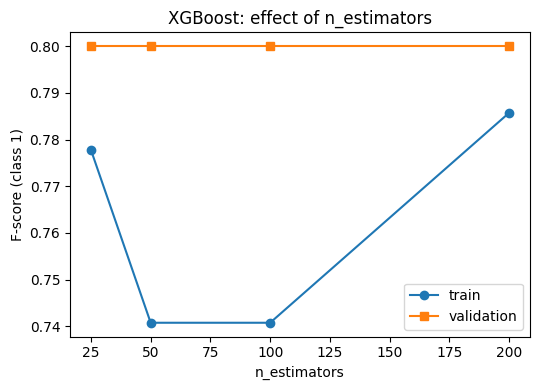

In [10]:
# [BC 5] XGBoost tuning on VALIDATION (stage 1, then stage 2)
bc_xgb_grid = {"n_estimators": [25, 50, 100, 200],
               "max_depth": [1, 2, 3, 4],
               "learning_rate": [0.05, 0.1, 0.3]}
bc_xgb_table = run_grid(lambda **p: XGBClassifier(random_state=SEED, **p), bc_xgb_grid,
                        bc_X_train, bc_y_train, bc_X_val, bc_y_val, bc_score, higher_is_better=True)
display(bc_xgb_table.head(10))
bc_xgb_best = best_params(bc_xgb_table, bc_xgb_grid.keys())
bc_xgb_table.to_csv("results/bc_xgb_tuning.csv", index=False)

bc_xgb_grid2 = {"subsample": [1.0, 0.8, 0.6], "colsample_bytree": [1.0, 0.8, 0.6], "min_child_weight": [1, 2, 3]}
bc_xgb_table2 = run_grid(lambda **p: XGBClassifier(random_state=SEED, **bc_xgb_best, **p), bc_xgb_grid2,
                         bc_X_train, bc_y_train, bc_X_val, bc_y_val, bc_score, higher_is_better=True)
display(bc_xgb_table2.head(5))
bc_xgb_best = {**bc_xgb_best, **best_params(bc_xgb_table2, bc_xgb_grid2.keys())}
bc_xgb_val_score = float(bc_xgb_table2.loc[0, "val_score"])
bc_xgb_table2.to_csv("results/bc_xgb_tuning_stage2.csv", index=False)
print("final XGBoost settings:", bc_xgb_best, "| validation F1:", round(bc_xgb_val_score, 4))
plot_param_effect(bc_xgb_table, "n_estimators", "F-score (class 1)", "figures/bc_xgb_trees_curve.png",
                  "XGBoost: effect of n_estimators")

In [11]:
# [BC 6] FINAL evaluation on the TEST set (threshold 0.5 for the confusion matrix, all probabilities for the PR curve)
bc_dt = DecisionTreeClassifier(random_state=SEED, **bc_dt_best).fit(bc_X_train, bc_y_train)
bc_xgb = XGBClassifier(random_state=SEED, **bc_xgb_best).fit(bc_X_train, bc_y_train)

bc_results, bc_curves, bc_test_pred, bc_test_prob = {}, {}, {}, {}
for name, model in [("Decision Tree", bc_dt), ("XGBoost", bc_xgb)]:
    pred = np.asarray(model.predict(bc_X_test)).astype(int)
    prob = np.asarray(model.predict_proba(bc_X_test))[:, 1]          # probability of class 1
    m = binary_metrics(bc_y_test, pred)
    P, R, T = pr_curve_np(bc_y_test, prob)
    m["average_precision"] = average_precision_np(P, R)
    bc_results[name] = m
    bc_curves[name] = (P, R, m["average_precision"])
    bc_test_pred[name], bc_test_prob[name] = pred, prob
    print(f"\n=== {name} (TEST) ===")
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in m.items()})
    print("confusion matrix [[TN, FP], [FN, TP]]:"); print(np.array(m["confusion_matrix"]))


=== Decision Tree (TEST) ===
{'accuracy': 0.8462, 'precision': 0.6, 'recall': 1.0, 'f1': 0.75, 'confusion_matrix': [[8, 2], [0, 3]], 'average_precision': 0.5333}
confusion matrix [[TN, FP], [FN, TP]]:
[[8 2]
 [0 3]]

=== XGBoost (TEST) ===
{'accuracy': 0.8462, 'precision': 0.6, 'recall': 1.0, 'f1': 0.75, 'confusion_matrix': [[8, 2], [0, 3]], 'average_precision': 0.9167}
confusion matrix [[TN, FP], [FN, TP]]:
[[8 2]
 [0 3]]


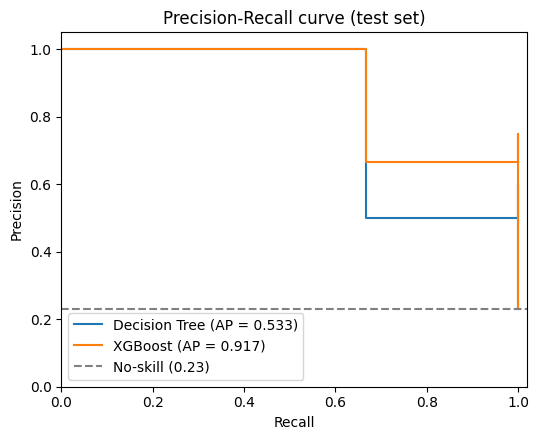

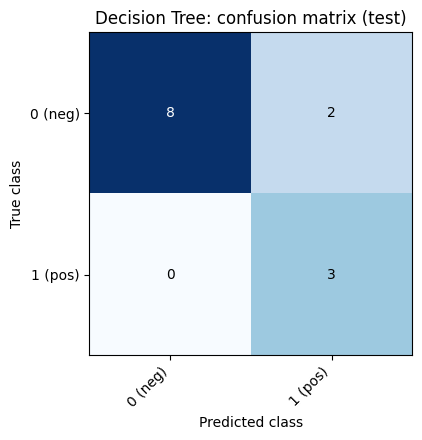

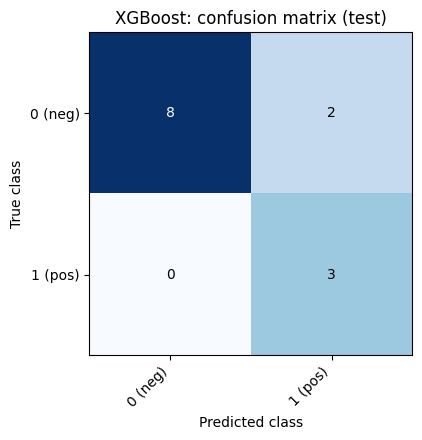

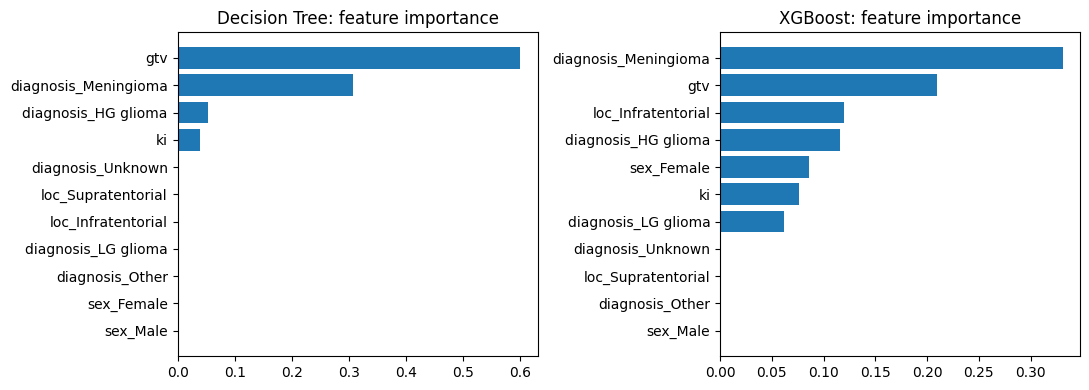

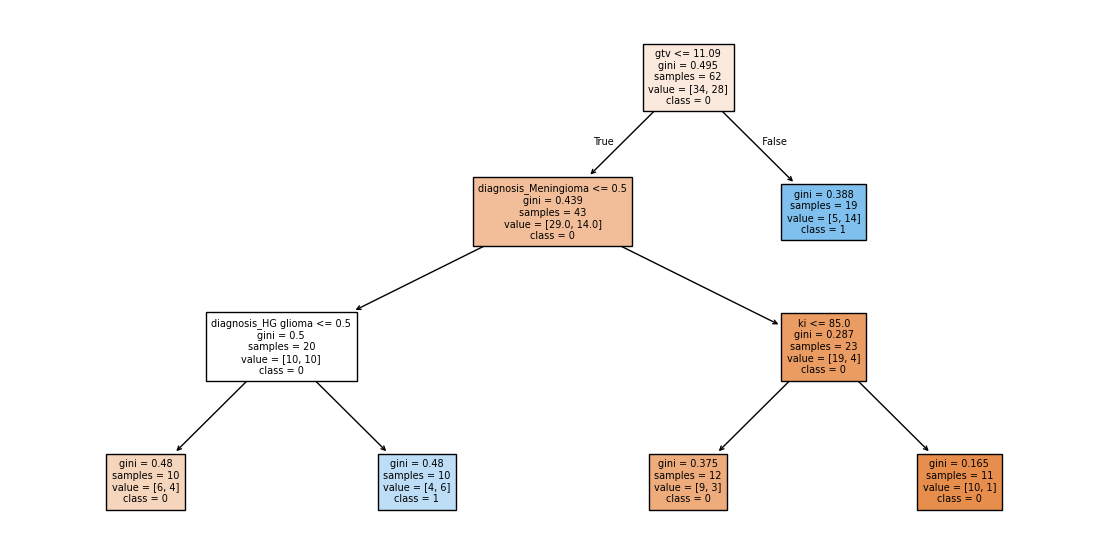

In [12]:
# [BC 7] Figures: PR curves (both models on ONE plot), confusion matrices, importances, tree
bc_pos_rate = float(bc_y_test.mean())
plot_pr_curves(bc_curves, bc_pos_rate, "Precision-Recall curve (test set)", "figures/bc_pr_curve.png")
for name, key in [("Decision Tree", "dt"), ("XGBoost", "xgb")]:
    plot_confusion(bc_results[name]["confusion_matrix"], ["0 (neg)", "1 (pos)"],
                   f"{name}: confusion matrix (test)", f"figures/bc_{key}_confusion.png")
plot_importances(bc_features, {"Decision Tree": bc_dt.feature_importances_,
                               "XGBoost": bc_xgb.feature_importances_}, "figures/bc_feature_importance.png")
plt.figure(figsize=(14, 7))
plot_tree(bc_dt, feature_names=bc_features, class_names=["0", "1"], filled=True, max_depth=3, fontsize=7)
plt.savefig("figures/bc_dt_tree.png", dpi=300, bbox_inches="tight"); plt.show()

In [13]:
# [BC 8] Save everything the report needs
bc_summary = {
    "dataset": "DT-BrainCancer", "n_rows": int(len(bc_df)), "features": bc_features, "positive_class": "status = 1",
    "dropped_columns": ["Unnamed: 0"], "missing_diagnosis_filled_with_Unknown": bc_n_missing,
    "seed": SEED, "shuffled_before_split": False,
    "split_sizes": {"train": len(bc_train), "val": len(bc_val), "test": len(bc_test)}, "split_counts": bc_split_counts,
    "baseline_always_predict_0_test": bc_baseline, "selection_metric": "F-score of class 1 on validation",
    "dt_grid": bc_dt_grid, "dt_best": bc_dt_best, "dt_val_score": bc_dt_val_score,
    "xgb_grid_stage1": bc_xgb_grid, "xgb_grid_stage2": bc_xgb_grid2, "xgb_best": bc_xgb_best, "xgb_val_score": bc_xgb_val_score,
    "test_results": bc_results,
    "versions": {"sklearn": sklearn.__version__, "xgboost": xgboost.__version__, "pandas": pd.__version__}}
save_json(bc_summary, "results/bc_summary.json")
pd.DataFrame({"y_true": bc_y_test, "dt_pred": bc_test_pred["Decision Tree"], "dt_prob": bc_test_prob["Decision Tree"],
              "xgb_pred": bc_test_pred["XGBoost"], "xgb_prob": bc_test_prob["XGBoost"]}).to_csv("results/bc_test_predictions.csv", index=False)
for name, key in [("Decision Tree", "dt"), ("XGBoost", "xgb")]:
    P, R, _ = bc_curves[name]
    pd.DataFrame({"recall": R, "precision": P}).to_csv(f"results/bc_{key}_pr_curve_points.csv", index=False)
print("saved.")

saved.
